# 01 · Construção da Base de Conhecimento

**Tech Challenge – Fase 4 · Voice of Customer Intelligence com RAG** · RM371084

Este notebook documenta e justifica a primeira etapa da solução: transformar as avaliações da
[base pública da Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) em uma base de conhecimento vetorial.

| Etapa | Decisão |
|---|---|
| Seleção dos dados | Apenas avaliações com título ou comentário informativo; metadados de pedido, entrega, produto e cliente via *joins* |
| Limpeza | Limpeza leve (quebras de linha, espaços, pontuação repetida); sem *lowercase*, *stemming* ou remoção de *stopwords* |
| Valores ausentes | Sem texto → descartada (não há o que recuperar); metadado ausente → rótulo explícito ou chave omitida |
| Organização | 1 avaliação = 1 documento (sem *chunking*), título + comentário, ID = `review_id` |
| Embeddings | `intfloat/multilingual-e5-small` (local, multilíngue, busca assimétrica, 384 dim.) |
| Armazenamento | ChromaDB persistente, índice HNSW com distância cosseno, metadados filtráveis |

In [1]:
import sys, json
sys.path.insert(0, "../src")
import pandas as pd
import matplotlib.pyplot as plt
from vocrag import config, data_prep

pd.set_option("display.max_colwidth", 150)
raw = data_prep.load_raw()
{k: v.shape for k, v in raw.items()}

{'reviews': (99224, 7),
 'orders': (99441, 8),
 'items': (112650, 7),
 'products': (32951, 9),
 'customers': (99441, 5)}

## 1. Análise exploratória das avaliações

A tabela `olist_order_reviews_dataset` tem uma avaliação por pedido, com nota (1–5), título e comentário opcionais.

In [2]:
rev = raw["reviews"]
missing = rev[["review_comment_title", "review_comment_message"]].isna().mean().mul(100).round(1)
print("% de valores ausentes:"); print(missing.to_string())
has_text = rev["review_comment_title"].notna() | rev["review_comment_message"].notna()
print(f"\nAvaliações com algum texto: {has_text.sum():,} de {len(rev):,} ({has_text.mean():.1%})")

% de valores ausentes:
review_comment_title      88.3
review_comment_message    58.7

Avaliações com algum texto: 42,706 de 99,224 (43.0%)


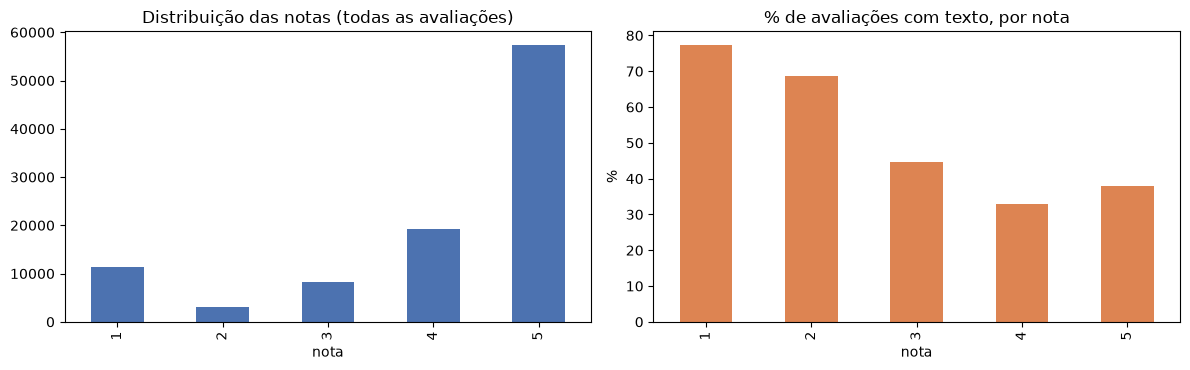

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rev["review_score"].value_counts().sort_index().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribuição das notas (todas as avaliações)"); axes[0].set_xlabel("nota")
rev.assign(tem_texto=has_text).groupby("review_score")["tem_texto"].mean().mul(100).plot.bar(ax=axes[1], color="#DD8452")
axes[1].set_title("% de avaliações com texto, por nota"); axes[1].set_xlabel("nota"); axes[1].set_ylabel("%")
plt.tight_layout()

**Leitura:** a maioria das notas é 5, mas clientes insatisfeitos escrevem comentários com muito mais frequência.
Por isso a base textual é proporcionalmente mais rica em reclamações do que a distribuição de notas sugere —
um ponto importante para interpretar qualquer “frequência” calculada sobre os textos.

## 2. Limpeza e preparação dos textos

Usamos um modelo de embeddings baseado em *transformer*, que se beneficia do texto natural: acentos, negações
(“**não** chegou”), maiúsculas e pontuação carregam significado. Assim, a limpeza é propositalmente leve:

* normalização Unicode (NFC), remoção de `\r\n` e espaços repetidos;
* redução de pontuação repetida (`!!!!!!` → `!!`);
* descarte de textos sem letras ou com menos de 3 caracteres (`"."`, `"10"`), que não têm conteúdo semântico.

In [4]:
exemplos = rev["review_comment_message"].dropna()
exemplos = exemplos[exemplos.str.contains(r"\r|\n|!!!|  ", regex=True)].head(5)
pd.DataFrame({"original": exemplos.map(repr), "limpo": exemplos.map(data_prep.clean_text)})

,original,limpo
12,"'Mas um pouco ,travando...pelo valor ta Boa.\r\n'","Mas um pouco ,travando..pelo valor ta Boa."
27,"'A compra foi realizada facilmente.\r\nA entrega foi efetuada muito antes do prazo dado.\r\nO produto já começou a ser usado e até o presente,\r\n...","A compra foi realizada facilmente. A entrega foi efetuada muito antes do prazo dado. O produto já começou a ser usado e até o presente, sem proble..."
51,'recebi somente 1 controle Midea Split ESTILO.\r\nFaltou Controle Remoto para Ar Condicionado Consul',recebi somente 1 controle Midea Split ESTILO. Faltou Controle Remoto para Ar Condicionado Consul
61,'Ocorreu tudo como contratado sendo a entrega realizada antes do prazo \r\n Estou satisfeita\r\n',Ocorreu tudo como contratado sendo a entrega realizada antes do prazo Estou satisfeita
69,"'Produto entregue como solicitado, e com muita brevidade. Parabéns!\r\n'","Produto entregue como solicitado, e com muita brevidade. Parabéns!"


In [5]:
for t in [".", "10", "ok", "Ótimo", "  Não recebi!!!!!!  "]:
    limpo = data_prep.clean_text(t)
    print(f"{t!r:28} -> {limpo!r:22} informativo={data_prep.is_informative(limpo)}")

'.'                          -> '.'                    informativo=False
'10'                         -> '10'                   informativo=False
'ok'                         -> 'ok'                   informativo=False
'Ótimo'                      -> 'Ótimo'                informativo=True
'  Não recebi!!!!!!  '       -> 'Não recebi!!'         informativo=True


## 3. Seleção, valores ausentes e organização dos documentos

`build_documents` executa as etapas e devolve estatísticas de cada uma:

1. **Seleção**: mantém avaliações com título *ou* comentário informativo. As ~57% sem texto são descartadas
   porque não contêm “voz do cliente” recuperável (a nota sozinha continua disponível como metadado nas análises).
2. **Duplicidade de `review_id`**: na base original o mesmo `review_id` aparece em mais de um pedido; mantemos um
   documento por avaliação para não duplicar evidências.
3. **Texto do documento**: `título + comentário` (o título é omitido quando já está contido no comentário).
   Títulos como “Péssimo” ou “Recomendo” reforçam o sentimento do comentário.
4. **Metadados** (via `orders`, `order_items`, `products`, `customers`): nota, sentimento, data, status do pedido,
   dias de entrega, atraso em relação ao prazo estimado, categoria principal (item de maior valor), valor, frete e UF.
5. **Ausentes nos metadados**: categoria/UF/status ausentes recebem rótulos explícitos (`sem_categoria`,
   `desconhecido`); campos numéricos ausentes (ex.: atraso de pedidos não entregues) são **omitidos** no índice em vez
   de preenchidos com um valor artificial, para não distorcer filtros e estatísticas.

In [6]:
docs, stats = data_prep.build_documents(raw)
print(json.dumps(stats, indent=2, ensure_ascii=False))

{
  "avaliacoes_totais": 99224,
  "sem_titulo_nem_comentario": 56537,
  "com_texto_informativo": 42275,
  "review_id_duplicados_removidos": 315,
  "documentos_finais": 41960,
  "textos_unicos": 34757
}


In [7]:
docs[["review_id", "text", "review_score", "sentiment", "product_category", "delivery_delay_days", "year_month", "customer_state"]].sample(8, random_state=7)

,review_id,text,review_score,sentiment,product_category,delivery_delay_days,year_month,customer_state
30519,4ca36ce04385c1e5a0c00ed7f153704b,Super Recomendo. Ótimo produto!,4,positivo,pet_shop,-25.0,2018-05,RS
14650,9795298d0dd2c3577f278fe62eb6a23d,Não recebi a grelha comprada. Gostaria de saber o que está ocorrendo.,1,negativo,utilidades_domesticas,-14.0,2017-12,ES
41037,00b6d2a442e4e49132990b557f2cf32f,Amei o produto. Super recomendo. Manual de instruções muito facil de entender.,5,positivo,bebes,-4.0,2018-08,SP
41917,05d3874965dd1ba4330bab86c5fff9aa,Produto faltando. Fiz o pedido de dois kits de progressiva e só me foi entregue um O que eu faço agora para pegar o produto faltante ?,1,negativo,beleza_saude,-12.0,2018-08,SP
3479,16d5a450df6592e049fc0e745175c311,super recomendado. loja mto boa,5,positivo,informatica_acessorios,-23.0,2017-05,MG
20335,42f52df35455509010ab94f4947d6b30,muito bom comprar na stark,5,positivo,cama_mesa_banho,-8.0,2018-02,SC
38507,7dde5d72fe17239a16d4071e9ee5a7d7,Onde está meu produto? Quero o meu produto onde está?,1,negativo,beleza_saude,7.0,2018-08,MG
33460,1cff169938927ffb0a12e47398ca63f5,"Eles são excelentes!! È o terceiro cubo que eu compro da targaryen via stark, e todos os três chegaram como deviam bem antes do prazo.",5,positivo,brinquedos,-21.0,2018-06,SP


count    41960.0
mean        11.8
std          9.7
min          1.0
25%          4.0
50%          9.0
75%         16.0
max         48.0


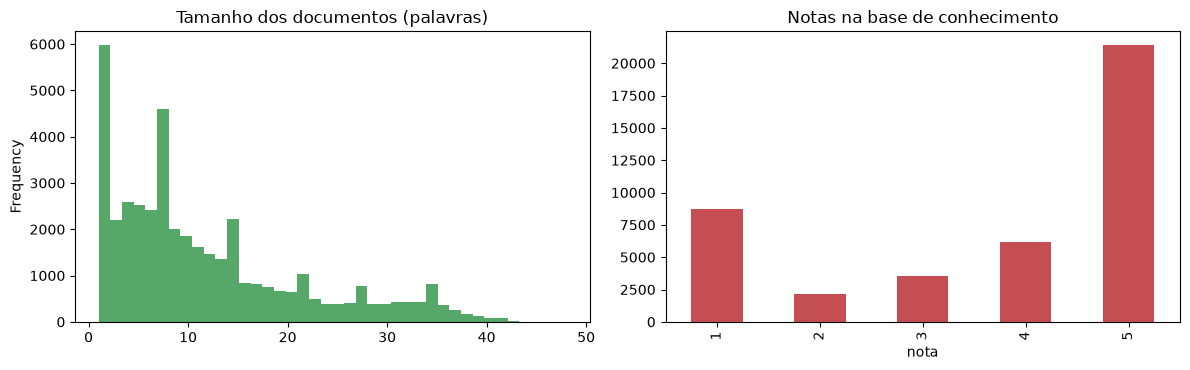

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
docs["text"].str.split().str.len().plot.hist(bins=40, ax=axes[0], color="#55A868")
axes[0].set_title("Tamanho dos documentos (palavras)")
docs["review_score"].value_counts().sort_index().plot.bar(ax=axes[1], color="#C44E52")
axes[1].set_title("Notas na base de conhecimento"); axes[1].set_xlabel("nota")
plt.tight_layout()
print(docs["text"].str.split().str.len().describe().round(1).to_string())

**Por que não fazer *chunking*?** Os documentos têm em média ~12 palavras (máximo ~50), muito abaixo do limite de
512 tokens do modelo. Cada avaliação já é uma unidade semântica completa (uma opinião de um cliente sobre um pedido),
e dividi-la separaria o problema da sua causa (“chegou quebrado / embalagem ruim”). Isso também garante que cada
evidência citada corresponda a exatamente uma avaliação real e rastreável pelo `review_id`.

In [9]:
top = docs["text_key"].value_counts().head(12)
print(f"Textos únicos: {docs['text_key'].nunique():,} de {len(docs):,} documentos")
top

Textos únicos: 34,757 de 41,960 documentos


text_key
otimo                   607
muito bom               604
bom                     460
recomendo               443
excelente               283
super recomendo         161
otimo produto           144
otima                   130
boa                     128
tudo ok                 118
nao recebi o produto    114
tudo certo               86
Name: count, dtype: int64

**Comentários idênticos** (“ótimo”, “muito bom”, “recomendo”) são mantidos na base, pois representam clientes
diferentes e contam para a frequência. Porém, na recuperação, eles são **deduplicados** (ver notebook 02) para não
ocuparem o contexto do LLM com informações repetidas — a quantidade de repetições é informada ao modelo.

## 4. Embeddings

**Modelo escolhido:** [`intfloat/multilingual-e5-small`](https://huggingface.co/intfloat/multilingual-e5-small)

* **Multilíngue com bom desempenho em português** (treinado em ~100 idiomas) — os textos são informais e com erros
  de digitação, e o modelo lida bem com isso por usar subpalavras.
* **Treinado para busca assimétrica** (pergunta curta ↔ passagem), exatamente o cenário do RAG. Usa os prefixos
  `query:` e `passage:`, aplicados automaticamente pelo código.
* **Leve e local** (118M parâmetros, 384 dimensões): indexa ~42 mil avaliações em poucos minutos em CPU, sem custo
  por chamada e sem enviar a base inteira a uma API externa. A troca de modelo é feita pela variável `EMBEDDING_MODEL`.
* Vetores **normalizados**, então a similaridade de cosseno é o produto interno.

In [10]:
from vocrag.indexing import embed_passages, embed_queries
frases = ["O produto chegou quebrado", "Recebi a mercadoria toda danificada", "O produto não chegou até hoje",
          "Entrega super rápida, recomendo", "Produto de ótima qualidade"]
consultas = ["produto chegou danificado", "meu pedido nunca foi entregue", "entrega rápida", "clientes satisfeitos com a qualidade"]
pv, qv = embed_passages(frases), embed_queries(consultas)
print("dimensão dos vetores:", pv.shape[1])
sim = pd.DataFrame(qv @ pv.T, index=consultas, columns=frases).round(3)
sim.style.highlight_max(axis=1, color="#c7e9c0").format("{:.3f}")

dimensão dos vetores: 384


,O produto chegou quebrado,Recebi a mercadoria toda danificada,O produto não chegou até hoje,"Entrega super rápida, recomendo",Produto de ótima qualidade
produto chegou danificado,0.929,0.908,0.886,0.849,0.876
meu pedido nunca foi entregue,0.851,0.858,0.857,0.826,0.815
entrega rápida,0.846,0.844,0.841,0.898,0.856
clientes satisfeitos com a qualidade,0.857,0.867,0.835,0.861,0.897


Para cada consulta, a frase mais similar (destacada) é a que tem o mesmo significado, mesmo com palavras diferentes
(“danificado” × “quebrado”, “nunca foi entregue” × “não chegou”) — algo que uma busca por palavras-chave não faria.

Note também que **todas** as similaridades ficam acima de ~0,83: o E5 produz uma escala “comprimida”. Por isso o
limiar de relevância usado para decidir se há evidências **não pode ser um valor genérico**; ele foi calibrado
empiricamente para esta base (notebook 02).

## 5. Armazenamento e indexação

**ChromaDB** em modo persistente (`data/chroma`):

* banco vetorial *open source*, embutido (sem servidor), simples de reproduzir a partir do repositório;
* índice **HNSW** (busca aproximada de vizinhos em tempo sub-linear) com distância **cosseno**;
* armazena **texto + vetor + metadados** juntos, permitindo **filtros por metadados** (`where`) na mesma consulta —
  base para a exploração contextual (nota, período, categoria, entrega).

O índice é criado pelo script `scripts/build_knowledge_base.py` (ou executando a célula abaixo com `REBUILD = True`).

In [11]:
REBUILD = False  # True para recriar o índice (alguns minutos em CPU)
from vocrag import indexing
if REBUILD:
    data_prep.run()
    indexing.build_index(docs)
col = indexing.get_collection()
print("Vetores no índice:", col.count())
print("Metadados da coleção:", col.metadata)
col.get(limit=2, include=["documents", "metadatas"])

Vetores no índice: 41960
Metadados da coleção: {'embedding_model': 'intfloat/multilingual-e5-small', 'hnsw:space': 'cosine'}


{'ids': ['69ac6a27fde9855ebeaaecac0f78058b',
  '6916ca4502d6d3bfd39818759d55d536'],
 'embeddings': None,
 'documents': ['MEU PEDIDO NÃO FOI ENTREGUE E NÃO FOI DADA NENHUMA SATISTAÇÃO',
  'nao recebi o produto e nem resposta da empresa'],
 'uris': None,
 'included': ['documents', 'metadatas'],
 'data': None,
 'metadatas': [{'order_status': 'canceled',
   'product_category': 'sem_categoria',
   'sentiment': 'negativo',
   'year_month': '2016-10',
   'order_id': '809a282bbd5dbcabb6f2f724fca862ec',
   'review_score': 1,
   'customer_state': 'SP',
   'year': 2016,
   'review_id': '69ac6a27fde9855ebeaaecac0f78058b',
   'text_key': 'meu pedido nao foi entregue e nao foi dada nenhuma satistacao'},
  {'review_id': '6916ca4502d6d3bfd39818759d55d536',
   'delivery_delay_days': 36,
   'sentiment': 'negativo',
   'review_score': 1,
   'delivery_days': 54,
   'year_month': '2016-10',
   'order_id': 'bfbd0f9bdef84302105ad712db648a6c',
   'order_status': 'delivered',
   'product_category': 'beleza_sau

## Resumo

A base de conhecimento final contém **uma avaliação por documento**, com texto limpo, embedding de 384 dimensões e
metadados de pedido/entrega/produto, indexada no ChromaDB. O próximo notebook (**02_pipeline_rag**) mostra como uma
pergunta percorre o pipeline de recuperação e geração.